# ACML Assignment 2: Convolutional Autoencoders

**Authors:** Simon Delecluse, Francesco Suriano

Goal: build a convolutional autoencoder (CAE) on CIFAR-10, study the latent space and architecture variations, then use it to colourise grayscale images.

## 0. Setup

In [2]:
import os
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import torchvision

from skimage.color import rgb2lab, lab2rgb

In [21]:
SEED = 456
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
EPOCHS = 50          # upper bound, early stopping usually ends sooner
LR = 2e-3
PATIENCE = 5         # early stopping: epochs without val improvement before stopping
LR_PATIENCE = 2      # scheduler: epochs without val improvement before lowering the LR
LR_FACTOR = 0.5      # scheduler: multiply LR by this factor

# trained models and their histories are saved here, so re-running the notebook doesn't retrain everything
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print(DEVICE)

cuda


## 1. Data
CIFAR-10 (60 000 colour images, 32x32x3). As suggested in the PDF we use `torchvision.datasets.CIFAR10`.
The official train (50k) and test (10k) sets are merged, shuffled and re-split **80 / 10 / 10** into train / validation / test (48k / 6k / 6k).
Pixels are normalised from [0, 255] to **[0, 1]**, which matches the sigmoid output of the decoder.

In [4]:
# Load CIFAR-10: merge the official train (50k) and test (10k) sets -> 60k images
train_set = torchvision.datasets.CIFAR10(root="./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root="./data", train=False, download=True)
x = np.concatenate([train_set.data, test_set.data])     # (60000, 32, 32, 3), uint8
x = torch.from_numpy(x).permute(0, 3, 1, 2)              # -> (N, C, H, W) as PyTorch expects

# Normalise from [0, 255] to [0, 1]
x = x.float() / 255.0

# Shuffle and split 80 / 10 / 10
n = len(x)
idx = torch.randperm(n, generator=torch.Generator().manual_seed(SEED))
n_train, n_val = int(0.8 * n), int(0.1 * n)
x_train = x[idx[:n_train]]
x_val = x[idx[n_train:n_train + n_val]]
x_test = x[idx[n_train + n_val:]]

# DataLoaders: input = target for reconstruction
train_loader = DataLoader(TensorDataset(x_train, x_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(x_val, x_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(x_test, x_test), batch_size=BATCH_SIZE)

print("all  :", tuple(x.shape), f"range [{x.min():.1f}, {x.max():.1f}]")
print("train:", tuple(x_train.shape))
print("val  :", tuple(x_val.shape))
print("test :", tuple(x_test.shape))

100%|██████████| 170M/170M [37:24<00:00, 76.0kB/s]   


all  : (60000, 3, 32, 32) range [0.0, 1.0]
train: (48000, 3, 32, 32)
val  : (6000, 3, 32, 32)
test : (6000, 3, 32, 32)


## 2. Helpers: training, evaluation, plotting
Training uses **Adam** with **MSE** loss, plus:
- **Learning-rate scheduling** (`ReduceLROnPlateau`): when the validation loss stops improving for `LR_PATIENCE` epochs, the LR is multiplied by `LR_FACTOR`.
- **Early stopping**: if the validation loss has not improved for `PATIENCE` epochs, training stops and the weights from the best epoch are restored.

`train_or_load` saves each trained model with its history in `results/`, so a second run of the notebook just loads them.

In [5]:
def evaluate(model, loader, loss_fn=None):
    """Average loss over a loader (used for val and test error)."""
    loss_fn = loss_fn or nn.MSELoss()
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            total += loss_fn(model(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n


def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, loss_fn=None,
                patience=PATIENCE, lr_patience=LR_PATIENCE, lr_factor=LR_FACTOR, verbose=True):
    """Train with Adam + MSE, LR scheduling and early stopping.
    Returns history dict with train_loss, val_loss and lr per epoch, plus best_epoch."""
    loss_fn = loss_fn or nn.MSELoss()
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min",
                                                           factor=lr_factor, patience=lr_patience)
    history = {"train_loss": [], "val_loss": [], "lr": []}

    # early stopping state
    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_no_improve = 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
            n += len(xb)

        train_loss = total / n
        val_loss = evaluate(model, val_loader, loss_fn)
        current_lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["lr"].append(current_lr)

        if verbose:
            print(f"epoch {epoch:3d} | train {train_loss:.5f} | val {val_loss:.5f} "
                  f"| lr {current_lr:.1e} | {time.time() - t0:.1f}s")

        scheduler.step(val_loss)

        # early stopping: keep the best weights, stop after `patience` epochs without improvement
        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                if verbose:
                    print(f"Early stopping at epoch {epoch} (best epoch {best_epoch}, val {best_loss:.5f})")
                break

    model.load_state_dict(best_state)   # restore the best weights
    history["best_epoch"] = best_epoch
    return history


def plot_learning_curve(history, title=""):
    """Train and val loss over epochs, with the learning rate on a second axis."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(epochs, history["train_loss"], label="train")
    ax.plot(epochs, history["val_loss"], label="validation")
    if "best_epoch" in history:
        ax.axvline(history["best_epoch"], color="gray", ls="--", lw=1, label="best epoch")
    ax.set_xlabel("epoch")
    ax.set_ylabel("MSE")
    ax.set_title(title)

    ax2 = ax.twinx()
    ax2.plot(epochs, history["lr"], color="tab:red", alpha=0.4, ls=":", label="learning rate")
    ax2.set_ylabel("learning rate")
    ax2.set_yscale("log")

    lines = ax.get_legend_handles_labels()
    lines2 = ax2.get_legend_handles_labels()
    ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="upper right")
    plt.tight_layout()
    plt.show()


def show_reconstructions(model, x, n=8, title=""):
    """Originals on top row, reconstructions below."""
    model.eval()
    with torch.no_grad():
        rec = model(x[:n].to(DEVICE)).cpu()
    fig, axes = plt.subplots(2, n, figsize=(1.5 * n, 3.2))
    for i in range(n):
        axes[0, i].imshow(x[i].permute(1, 2, 0).numpy())
        axes[1, i].imshow(rec[i].clamp(0, 1).permute(1, 2, 0).numpy())
        axes[0, i].axis("off")
        axes[1, i].axis("off")
    axes[0, 0].set_title("original", loc="left", fontsize=9)
    axes[1, 0].set_title("reconstruction", loc="left", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def train_or_load(name, model, train_loader, val_loader, test_loader, epochs=EPOCHS, **kwargs):
    """Train the model and save it to results/<name>.pt, or load it if it was already trained."""
    path = os.path.join(RESULTS_DIR, f"{name}.pt")
    if os.path.exists(path):
        saved = torch.load(path, map_location=DEVICE)
        model.load_state_dict(saved["state_dict"])
        model.to(DEVICE)
        print(f"loaded {name} from {path}")
        return saved["history"]

    t0 = time.time()
    history = train_model(model, train_loader, val_loader, epochs=epochs, **kwargs)
    history["train_time"] = time.time() - t0
    history["test_loss"] = evaluate(model, test_loader, kwargs.get("loss_fn"))
    torch.save({"state_dict": model.state_dict(), "history": history}, path)
    return history


def predict(model, x, batch_size=500):
    """Run the model on a tensor in batches and return the output on the CPU."""
    model.eval()
    outputs = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            outputs.append(model(x[i:i + batch_size].to(DEVICE)).cpu())
    return torch.cat(outputs)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def latent_size(model, input_shape=(1, 3, 32, 32)):
    """Run a dummy input through the encoder and return the latent shape and number of elements."""
    with torch.no_grad():
        z = model.encode(torch.zeros(input_shape, device=next(model.parameters()).device))
    return tuple(z.shape[1:]), z[0].numel()

## 3. Exercise 1: Reconstruction with the given CAE
Architecture from the PDF (padding "same", stride 1 for convs, ReLU):

`Conv 3x3 (8) -> MaxPool 2x2 -> Conv 3x3 (12) -> MaxPool 2x2 -> Conv 3x3 (16) -> Upsample 2x2 -> Conv 3x3 (12) -> Upsample 2x2 -> Conv 3x3 (3)`

**Stride** is the step (in pixels) the filter moves between two positions.
- Conv layers use **stride 1**: the 3x3 filter is applied at every pixel, so with padding 1 the spatial size stays 32 -> 32.
- Pooling uses **stride 2** (the default, equal to the 2x2 window): windows don't overlap, so the size halves 32 -> 16 -> 8.
- Upsampling 2x2 does the reverse, repeating each pixel into a 2x2 block: 8 -> 16 -> 32.

The **encoder** (conv, pool, conv, pool, conv) compresses the image to a latent code of 8x8x16. The **decoder** (upsample, conv, upsample, conv) reconstructs the 32x32x3 image from it.
The last layer uses a **sigmoid** so the output is in [0, 1], like the normalised input.

In [6]:
class CAE(nn.Module):
    """Baseline convolutional autoencoder from the assignment."""

    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, stride=1, padding=1),    # 32x32x8
            nn.ReLU(),
            nn.MaxPool2d(2),                                       # 16x16x8
            nn.Conv2d(8, 12, kernel_size=3, stride=1, padding=1),   # 16x16x12
            nn.ReLU(),
            nn.MaxPool2d(2),                                       # 8x8x12
            nn.Conv2d(12, 16, kernel_size=3, stride=1, padding=1),  # 8x8x16  <- latent
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2),                            # 16x16x16
            nn.Conv2d(16, 12, kernel_size=3, stride=1, padding=1),  # 16x16x12
            nn.ReLU(),
            nn.Upsample(scale_factor=2),                            # 32x32x12
            nn.Conv2d(12, 3, kernel_size=3, stride=1, padding=1),   # 32x32x3
            nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        return self.decode(self.encode(x))


model = CAE().to(DEVICE)
print(model)
print("parameters:", count_params(model))
print("latent:", latent_size(model))

CAE(
  (encoder): Sequential(
    (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(12, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
  )
  (decoder): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(16, 12, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): Conv2d(12, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)
parameters: 4911
latent: ((16, 8, 8), 1024)


loaded ex1_baseline from results\ex1_baseline.pt


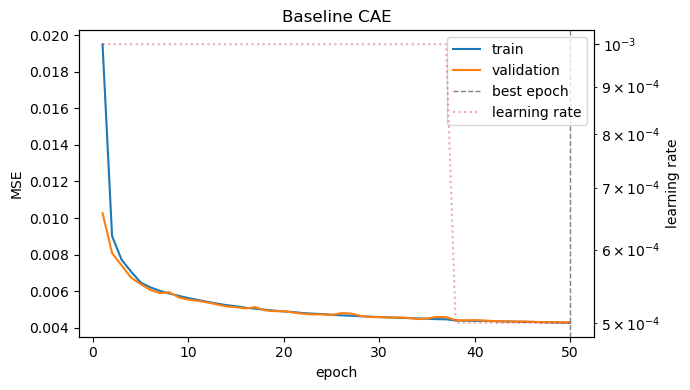

Test MSE: 0.00428164962058266


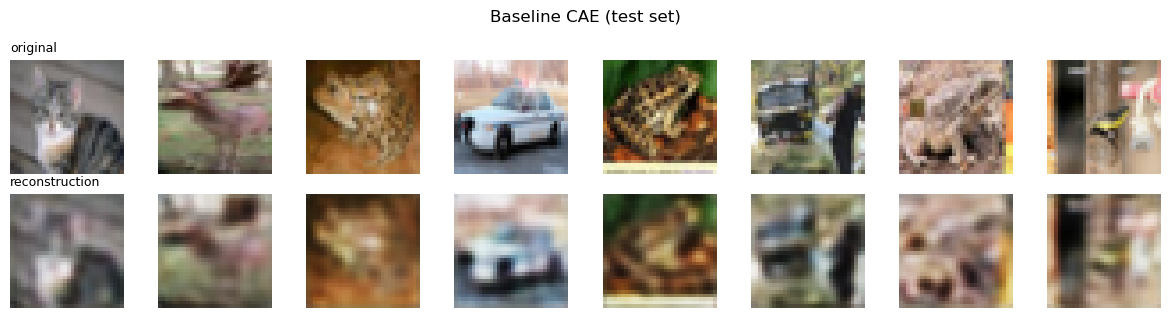

In [7]:
history = train_or_load("ex1_baseline", model, train_loader, val_loader, test_loader)
plot_learning_curve(history, "Baseline CAE")
print("Test MSE:", history["test_loss"])
show_reconstructions(model, x_test, title="Baseline CAE (test set)")

**Discussion.** _To be written from the final run._

## 4. Exercise 2: Latent space and architecture variations
### 4.1 Latent space size of the baseline
Each layer's output is $\left(\frac{W-K+2P}{S}+1\right)^2 \times C$. For the encoder:

| layer | W | K | P | S | C | output | size |
|---|---|---|---|---|---|---|---|
| conv 3x3 | 32 | 3 | 1 | 1 | 8 | 32x32x8 | 8192 |
| max pool 2x2 | 32 | 2 | 0 | 2 | 8 | 16x16x8 | 2048 |
| conv 3x3 | 16 | 3 | 1 | 1 | 12 | 16x16x12 | 3072 |
| max pool 2x2 | 16 | 2 | 0 | 2 | 12 | 8x8x12 | 768 |
| conv 3x3 | 8 | 3 | 1 | 1 | 16 | 8x8x16 | **1024** |

The latent space is **8x8x16 = 1024** values. The input has 32x32x3 = 3072, so the encoder compresses it by a factor of 3.

In [8]:
def conv_output_size(W, K, P, S):
    """Output width of a conv/pool layer, from the formula in the PDF."""
    return (W - K + 2 * P) // S + 1


def layer_sizes_table(model, input_shape=(1, 3, 32, 32)):
    """Pass a dummy image through the model and print the shape after every layer."""
    x = torch.zeros(input_shape, device=next(model.parameters()).device)
    print(f"{'input':<28}{'x'.join(map(str, [x.shape[2], x.shape[3], x.shape[1]])):>12}{x[0].numel():>8}")
    with torch.no_grad():
        for part in ["encoder", "decoder"]:
            for layer in getattr(model, part):
                x = layer(x)
                if isinstance(layer, (nn.ReLU, nn.Sigmoid, nn.Tanh)):
                    continue
                shape = f"{x.shape[2]}x{x.shape[3]}x{x.shape[1]}"
                print(f"{part + ': ' + layer.__class__.__name__:<28}{shape:>12}{x[0].numel():>8}")


# hand calculation with the formula
W = 32
for name, K, P, S, C in [("conv 3x3", 3, 1, 1, 8), ("pool 2x2", 2, 0, 2, 8), ("conv 3x3", 3, 1, 1, 12),
                         ("pool 2x2", 2, 0, 2, 12), ("conv 3x3", 3, 1, 1, 16)]:
    W = conv_output_size(W, K, P, S)
    print(f"{name}: {W}x{W}x{C} = {W * W * C}")
print()

# check against the actual model
layer_sizes_table(CAE())

conv 3x3: 32x32x8 = 8192
pool 2x2: 16x16x8 = 2048
conv 3x3: 16x16x12 = 3072
pool 2x2: 8x8x12 = 768
conv 3x3: 8x8x16 = 1024

input                            32x32x3    3072
encoder: Conv2d                  32x32x8    8192
encoder: MaxPool2d               16x16x8    2048
encoder: Conv2d                 16x16x12    3072
encoder: MaxPool2d                8x8x12     768
encoder: Conv2d                   8x8x16    1024
decoder: Upsample               16x16x16    4096
decoder: Conv2d                 16x16x12    3072
decoder: Upsample               32x32x12   12288
decoder: Conv2d                  32x32x3    3072


### 4.2 Other architectures
To compare architectures we use one flexible class instead of writing a new one each time:
- `enc_channels`: channels of each encoder stage. Every stage ends with a 2x downsampling, so the number of stages sets the **depth** and the spatial size of the latent space (1 stage: 16x16, 2: 8x8, 3: 4x4).
- `latent_channels`: channels of the bottleneck conv. Together with the depth this sets the **latent size**.
- `kernel_size`: filter size, padding is always `kernel_size // 2` so it stays "same".
- `convs_per_stage`: extra conv layers per stage (more depth without changing the latent size).
- `downsample`: `"pool"` (max pool + upsample, as in the PDF) or `"stride"` (conv with **stride 2** in the encoder and a learned `ConvTranspose2d` in the decoder).

The decoder mirrors the encoder. With the defaults the class builds exactly the baseline from Exercise 1.

We left padding at "same" everywhere. Without it every conv shrinks the image (32 -> 30 -> ...) and the decoder no longer ends at 32x32, so it would only add cropping work without telling us much.

In [9]:
class ConfigurableCAE(nn.Module):
    def __init__(self, enc_channels=(8, 12), latent_channels=16, kernel_size=3, convs_per_stage=1,
                 downsample="pool", in_ch=3, out_ch=3, out_act="sigmoid"):
        super().__init__()
        k, p = kernel_size, kernel_size // 2

        # encoder: each stage = conv(s) + downsampling by 2
        layers = []
        c_prev = in_ch
        for c in enc_channels:
            for i in range(convs_per_stage):
                last = i == convs_per_stage - 1
                stride = 2 if (last and downsample == "stride") else 1
                layers += [nn.Conv2d(c_prev, c, k, stride=stride, padding=p), nn.ReLU()]
                c_prev = c
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2))
        layers += [nn.Conv2d(c_prev, latent_channels, k, padding=p), nn.ReLU()]
        self.encoder = nn.Sequential(*layers)

        # decoder: each stage = upsampling by 2 + conv(s), mirroring the encoder
        rev = list(reversed(enc_channels))
        targets = rev[:-1] + [out_ch]   # baseline: (12, 3)
        layers = []
        c_prev = latent_channels
        for j, target in enumerate(targets):
            if downsample == "pool":
                layers.append(nn.Upsample(scale_factor=2))
            else:
                layers += [nn.ConvTranspose2d(c_prev, c_prev, 2, stride=2), nn.ReLU()]
            for i in range(convs_per_stage):
                last = i == convs_per_stage - 1
                c_out = target if last else rev[j]
                layers.append(nn.Conv2d(c_prev, c_out, k, padding=p))
                c_prev = c_out
                if not (last and j == len(targets) - 1):
                    layers.append(nn.ReLU())
        layers.append(nn.Sigmoid() if out_act == "sigmoid" else nn.Tanh())
        self.decoder = nn.Sequential(*layers)

    def encode(self, x):
        return self.encoder(x)

    def forward(self, x):
        return self.decoder(self.encoder(x))


# sanity check: the default config is the baseline
print("baseline params:", count_params(CAE()), "| ConfigurableCAE() params:", count_params(ConfigurableCAE()))

baseline params: 4911 | ConfigurableCAE() params: 4911


**Experiments.** Each one changes one thing compared to the baseline:
1. **Latent channels** 4, 8, 16, 32, 64 with everything else fixed: latent sizes from 256 to 4096. This is the cleanest test of latent size vs error.
2. **Same latent size (1024), different shape**: 16x16x4 (1 stage), 8x8x16 (baseline), 4x4x64 (3 stages). Is spatial resolution or the number of channels more useful?
3. **Depth**: 3 stages with 16 latent channels (4x4x16 = 256), and 2 convs per stage.
4. **Kernel size** 5 and 7.
5. **Strided conv + transposed conv** instead of pooling + upsampling.
6. **Width**: 32 and 64 channels in the encoder, latent still 8x8x16. Much more capacity but the **same latent size**, which separates the effect of capacity from the effect of the latent size.

A full run of the baseline takes about 20 min on our CPU, so for the comparison every model gets the same budget of **15 epochs** (same seed, same early stopping and LR schedule). The model is chosen on **validation** MSE; the test MSE is only reported.

In [10]:
EXP_EPOCHS = 15

ARCHITECTURES = {
    # name: (group, config)
    "latent 8x8x4":       ("latent channels", dict(latent_channels=4)),
    "latent 8x8x8":       ("latent channels", dict(latent_channels=8)),
    "baseline 8x8x16":    ("latent channels", dict()),
    "latent 8x8x32":      ("latent channels", dict(latent_channels=32)),
    "latent 8x8x64":      ("latent channels", dict(latent_channels=64)),
    "1 stage 16x16x4":    ("same latent size", dict(enc_channels=(8,), latent_channels=4)),
    "3 stages 4x4x64":    ("same latent size", dict(enc_channels=(8, 12, 16), latent_channels=64)),
    "3 stages 4x4x16":    ("depth", dict(enc_channels=(8, 12, 16))),
    "2 convs per stage":  ("depth", dict(convs_per_stage=2)),
    "kernel 5x5":         ("kernel size", dict(kernel_size=5)),
    "kernel 7x7":         ("kernel size", dict(kernel_size=7)),
    "strided conv":       ("downsampling", dict(downsample="stride")),
    "wide (32, 64)":      ("width", dict(enc_channels=(32, 64))),
}


def run_experiments(architectures, epochs=EXP_EPOCHS):
    """Train every config (or load it) and collect the results in a table."""
    rows, models, histories = [], {}, {}
    for name, (group, config) in architectures.items():
        torch.manual_seed(SEED)
        model = ConfigurableCAE(**config).to(DEVICE)
        shape, size = latent_size(model)
        print(f"--- {name}: latent {shape}, {count_params(model)} params")
        history = train_or_load("ex2_" + name.replace(" ", "_"), model, train_loader, val_loader, test_loader,
                                epochs=epochs, verbose=False)
        rows.append({
            "name": name,
            "group": group,
            "latent": f"{shape[1]}x{shape[2]}x{shape[0]}",
            "latent size": size,
            "params": count_params(model),
            "best val MSE": min(history["val_loss"]),
            "test MSE": history["test_loss"],
            "epochs": len(history["val_loss"]),
            "time (min)": history["train_time"] / 60,
        })
        models[name] = model
        histories[name] = history
    return pd.DataFrame(rows).set_index("name"), models, histories

In [11]:
results, exp_models, exp_histories = run_experiments(ARCHITECTURES)
results.style.format({"best val MSE": "{:.5f}", "test MSE": "{:.5f}", "time (min)": "{:.1f}"})

--- latent 8x8x4: latent (4, 8, 8), 2307 params
loaded ex2_latent_8x8x4 from results\ex2_latent_8x8x4.pt
--- latent 8x8x8: latent (8, 8, 8), 3175 params
loaded ex2_latent_8x8x8 from results\ex2_latent_8x8x8.pt
--- baseline 8x8x16: latent (16, 8, 8), 4911 params
loaded ex2_baseline_8x8x16 from results\ex2_baseline_8x8x16.pt
--- latent 8x8x32: latent (32, 8, 8), 8383 params
loaded ex2_latent_8x8x32 from results\ex2_latent_8x8x32.pt
--- latent 8x8x64: latent (64, 8, 8), 15327 params
loaded ex2_latent_8x8x64 from results\ex2_latent_8x8x64.pt
--- 1 stage 16x16x4: latent (4, 16, 16), 627 params
loaded ex2_1_stage_16x16x4 from results\ex2_1_stage_16x16x4.pt
--- 3 stages 4x4x64: latent (64, 4, 4), 23423 params
loaded ex2_3_stages_4x4x64 from results\ex2_3_stages_4x4x64.pt
--- 3 stages 4x4x16: latent (16, 4, 4), 9551 params
loaded ex2_3_stages_4x4x16 from results\ex2_3_stages_4x4x16.pt
--- 2 convs per stage: latent (16, 8, 8), 8875 params
loaded ex2_2_convs_per_stage from results\ex2_2_convs_pe

,group,latent,latent size,params,best val MSE,test MSE,epochs,time (min)
name,,,,,,,,
latent 8x8x4,latent channels,8x8x4,256,2307,0.00590,0.00589,15,4.0
latent 8x8x8,latent channels,8x8x8,512,3175,0.00544,0.00543,15,4.6
baseline 8x8x16,latent channels,8x8x16,1024,4911,0.00512,0.00512,15,5.6
latent 8x8x32,latent channels,8x8x32,2048,8383,0.00517,0.00517,15,6.2
latent 8x8x64,latent channels,8x8x64,4096,15327,0.00496,0.00495,15,7.3
1 stage 16x16x4,same latent size,16x16x4,1024,627,0.00218,0.00218,15,3.3
3 stages 4x4x64,same latent size,4x4x64,1024,23423,0.01040,0.01041,15,7.5
3 stages 4x4x16,depth,4x4x16,256,9551,0.01122,0.01122,15,7.4
2 convs per stage,depth,8x8x16,1024,8875,0.00525,0.00521,15,10.9


In [12]:
def plot_latent_vs_error(results):
    """Scatter of latent size vs test MSE, one colour per experiment group."""
    fig, ax = plt.subplots(figsize=(8, 5))
    for group, df in results.groupby("group", sort=False):
        ax.scatter(df["latent size"], df["test MSE"], label=group, s=50)
        for name, row in df.iterrows():
            ax.annotate(name, (row["latent size"], row["test MSE"]), fontsize=8,
                        xytext=(4, 4), textcoords="offset points")
    ax.axvline(3 * 32 * 32, color="gray", ls="--", lw=1)
    ax.text(3 * 32 * 32, ax.get_ylim()[1], " input size (3072)", va="top", fontsize=8, color="gray")
    ax.set_xscale("log", base=2)
    ax.set_xlabel("latent size (number of values)")
    ax.set_ylabel("test MSE")
    ax.set_title("Latent size vs reconstruction error")
    ax.legend()
    plt.tight_layout()
    plt.show()


def plot_val_curves(histories, names):
    fig, ax = plt.subplots(figsize=(8, 4))
    for name in names:
        ax.plot(range(1, len(histories[name]["val_loss"]) + 1), histories[name]["val_loss"], label=name)
    ax.set_xlabel("epoch")
    ax.set_ylabel("validation MSE")
    ax.set_yscale("log")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def compare_reconstructions(models, x, n=6):
    """One row per model, plus the originals on top."""
    fig, axes = plt.subplots(len(models) + 1, n, figsize=(1.6 * n, 1.7 * (len(models) + 1)))
    rows = [("original", x[:n])] + [(name, predict(m, x[:n])) for name, m in models.items()]
    for r, (name, imgs) in enumerate(rows):
        for i in range(n):
            axes[r, i].imshow(imgs[i].clamp(0, 1).permute(1, 2, 0).numpy())
            axes[r, i].axis("off")
        axes[r, 0].set_title(name, loc="left", fontsize=9)
    plt.tight_layout()
    plt.show()

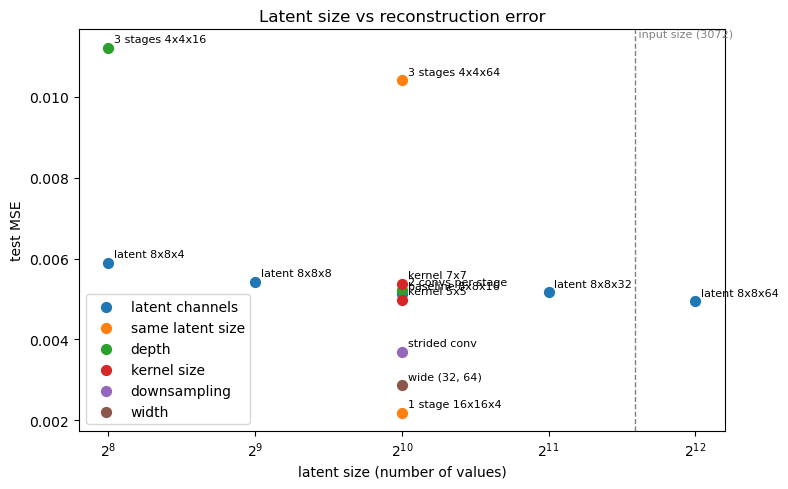

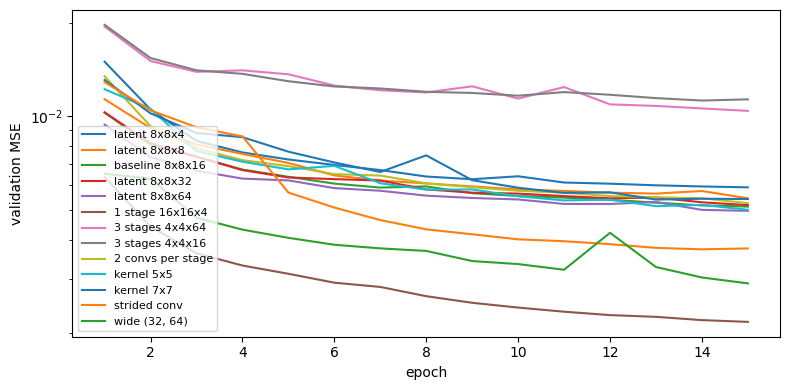

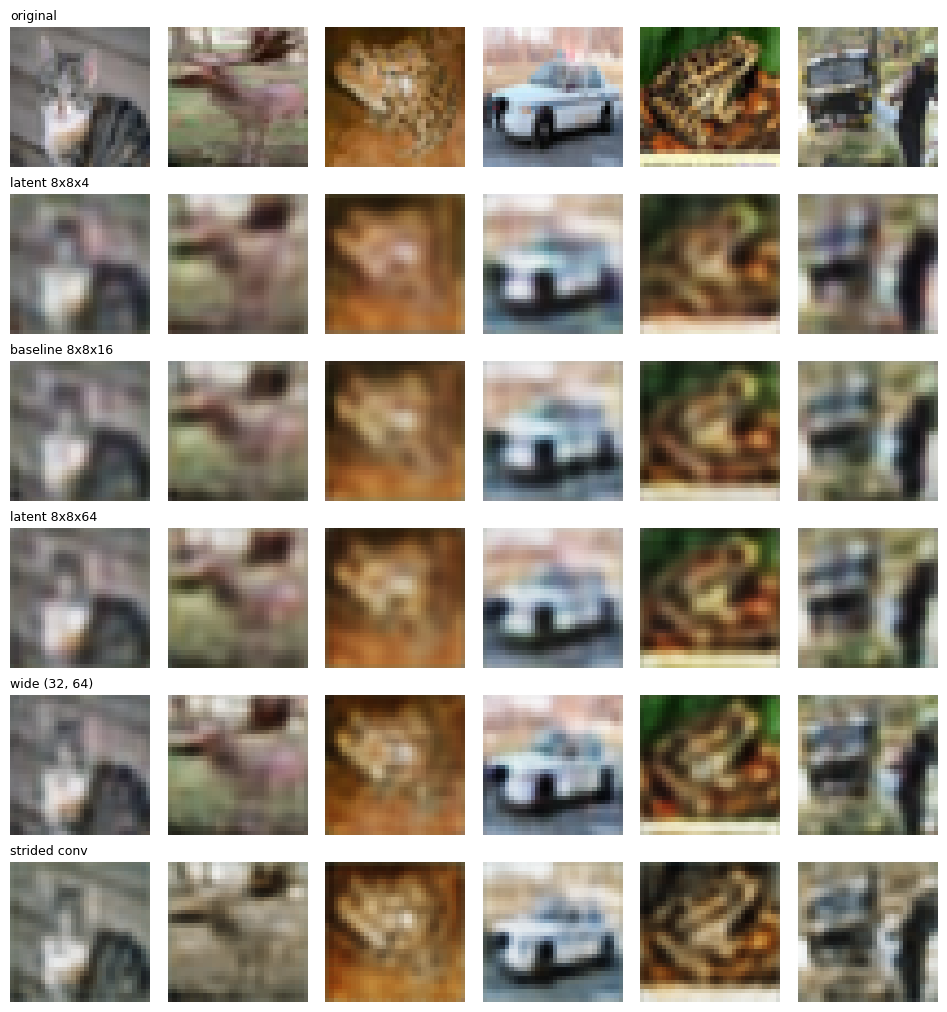

In [13]:
plot_latent_vs_error(results)
plot_val_curves(exp_histories, results.index)
compare_reconstructions({name: exp_models[name] for name in
                         ["latent 8x8x4", "baseline 8x8x16", "latent 8x8x64", "wide (32, 64)", "strided conv"]},
                        x_test)

In [14]:
# correlation between latent size and error, only over the clean "latent channels" experiment and over all runs
clean = results[results["group"] == "latent channels"]
print("corr(log latent size, test MSE), latent channel runs:",
      round(np.corrcoef(np.log2(clean["latent size"]), clean["test MSE"])[0, 1], 3))
print("corr(log latent size, test MSE), all runs:          ",
      round(np.corrcoef(np.log2(results["latent size"]), results["test MSE"])[0, 1], 3))

best_name = results["best val MSE"].idxmin()
best_config = ARCHITECTURES[best_name][1]
print("best architecture on validation:", best_name, best_config)

corr(log latent size, test MSE), latent channel runs: -0.924
corr(log latent size, test MSE), all runs:           -0.409
best architecture on validation: 1 stage 16x16x4 {'enc_channels': (8,), 'latent_channels': 4}


**Discussion.** _To be written from the final run._

## 5. Exercise 3: Colourisation
### 5.1 Grayscale -> RGB
The input is now a 1-channel grayscale image and the target is still the original RGB image. The grayscale image is computed with the standard luminance weights $0.299R + 0.587G + 0.114B$.
We reuse the best architecture of Exercise 2 with `in_ch=1`.

As a reference point we also compute the MSE of simply copying the grayscale value into all three channels. A model that learned anything about colour should beat this.

In [15]:
COL_EPOCHS = 30


def to_grayscale(x):
    """(N, 3, H, W) RGB -> (N, 1, H, W) luminance."""
    weights = torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1)
    return (x * weights).sum(dim=1, keepdim=True)


def show_rows(rows, n=8, title=""):
    """rows: dict label -> tensor of images (1 or 3 channels)."""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.6 * len(rows)))
    for r, (label, imgs) in enumerate(rows.items()):
        for i in range(n):
            img = imgs[i].clamp(0, 1)
            if img.shape[0] == 1:
                axes[r, i].imshow(img[0].numpy(), cmap="gray", vmin=0, vmax=1)
            else:
                axes[r, i].imshow(img.permute(1, 2, 0).numpy())
            axes[r, i].axis("off")
        axes[r, 0].set_title(label, loc="left", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


g_train, g_val, g_test = to_grayscale(x_train), to_grayscale(x_val), to_grayscale(x_test)
col_train_loader = DataLoader(TensorDataset(g_train, x_train), batch_size=BATCH_SIZE, shuffle=True)
col_val_loader = DataLoader(TensorDataset(g_val, x_val), batch_size=BATCH_SIZE)
col_test_loader = DataLoader(TensorDataset(g_test, x_test), batch_size=BATCH_SIZE)

gray_copy_mse = F.mse_loss(g_test.repeat(1, 3, 1, 1), x_test).item()
print("reference, grayscale copied to RGB, test MSE:", round(gray_copy_mse, 5))

reference, grayscale copied to RGB, test MSE: 0.00659


epoch   1 | train 0.01930 | val 0.01132 | lr 1.0e-03 | 2.1s
epoch   2 | train 0.01055 | val 0.00995 | lr 1.0e-03 | 2.1s
epoch   3 | train 0.00974 | val 0.00944 | lr 1.0e-03 | 1.8s
epoch   4 | train 0.00931 | val 0.00910 | lr 1.0e-03 | 2.4s
epoch   5 | train 0.00900 | val 0.00881 | lr 1.0e-03 | 2.2s
epoch   6 | train 0.00880 | val 0.00866 | lr 1.0e-03 | 1.9s
epoch   7 | train 0.00868 | val 0.00855 | lr 1.0e-03 | 1.8s
epoch   8 | train 0.00860 | val 0.00853 | lr 1.0e-03 | 1.7s
epoch   9 | train 0.00854 | val 0.00847 | lr 1.0e-03 | 2.0s
epoch  10 | train 0.00849 | val 0.00840 | lr 1.0e-03 | 1.7s
epoch  11 | train 0.00845 | val 0.00842 | lr 1.0e-03 | 1.6s
epoch  12 | train 0.00840 | val 0.00832 | lr 1.0e-03 | 1.6s
epoch  13 | train 0.00836 | val 0.00826 | lr 1.0e-03 | 1.6s
epoch  14 | train 0.00833 | val 0.00826 | lr 1.0e-03 | 1.7s
epoch  15 | train 0.00831 | val 0.00823 | lr 1.0e-03 | 1.8s
epoch  16 | train 0.00827 | val 0.00817 | lr 1.0e-03 | 1.9s
epoch  17 | train 0.00823 | val 0.00815 

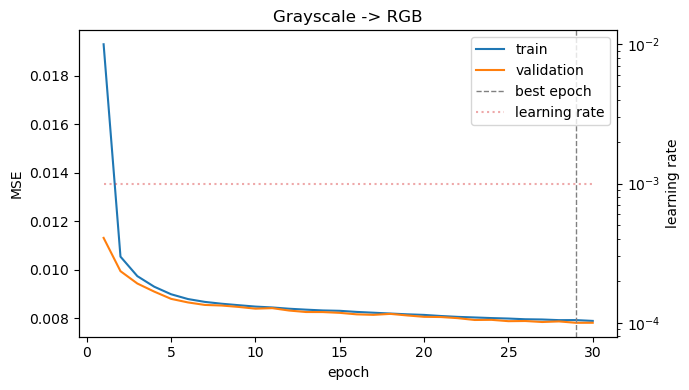

Test MSE: 0.007891081410149733


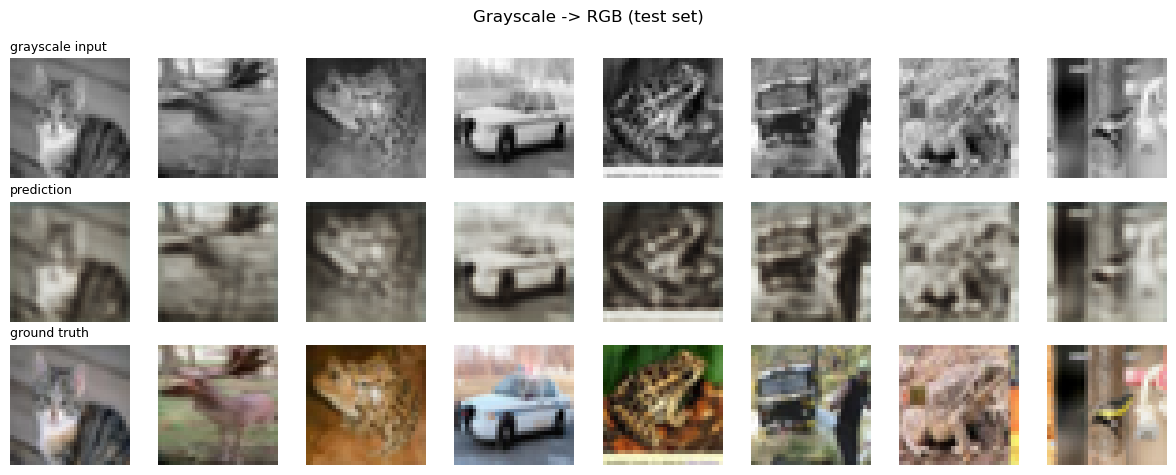

In [16]:
torch.manual_seed(SEED)
rgb_model = ConfigurableCAE(**best_config, in_ch=1, out_ch=3).to(DEVICE)
rgb_history = train_or_load("ex3_gray_to_rgb", rgb_model, col_train_loader, col_val_loader, col_test_loader,
                            epochs=COL_EPOCHS)
plot_learning_curve(rgb_history, "Grayscale -> RGB")
print("Test MSE:", rgb_history["test_loss"])

rgb_pred = predict(rgb_model, g_test)
show_rows({"grayscale input": g_test, "prediction": rgb_pred, "ground truth": x_test},
          title="Grayscale -> RGB (test set)")

### 5.2 Chrominance trick (Lab colour space)
In the Lab colour space, **L** is the lightness (basically the grayscale image) and **a**, **b** hold the colour (green-red and blue-yellow).
So we give the network L and only ask it to predict a and b. The edges and details are already in L, so the network doesn't have to reconstruct them, and at the end we stack the predicted ab on the real L and convert back to RGB.

L (0..100) is scaled to [0, 1] and ab (about -128..127) to [-1, 1], so the output layer uses **tanh**. The loss is MSE on ab. To compare with 5.1, we also compute the **RGB MSE** of the recombined images.

We also measure **colourfulness** as the mean chroma $\sqrt{a^2+b^2}$ of the predictions compared to the real images, to check if the colours come out washed out.

In [17]:
def rgb_to_lab(x, chunk=5000):
    """(N, 3, H, W) RGB in [0, 1] -> L in [0, 1] (N, 1, H, W) and ab in about [-1, 1] (N, 2, H, W)."""
    L, ab = [], []
    for i in range(0, len(x), chunk):   # in chunks, rgb2lab works in float64 and uses a lot of memory
        lab = rgb2lab(x[i:i + chunk].permute(0, 2, 3, 1).numpy())
        lab = torch.from_numpy(lab).float().permute(0, 3, 1, 2)
        L.append(lab[:, :1] / 100)
        ab.append(lab[:, 1:] / 128)
    return torch.cat(L), torch.cat(ab)


def lab_to_rgb(L, ab):
    """Inverse of rgb_to_lab, returns RGB in [0, 1]."""
    lab = torch.cat([L * 100, ab * 128], dim=1).permute(0, 2, 3, 1).numpy().astype(np.float64)
    rgb = lab2rgb(lab)
    return torch.from_numpy(rgb).float().permute(0, 3, 1, 2)


def chroma(ab):
    """Mean colour intensity sqrt(a^2 + b^2), in Lab units."""
    return (ab * 128).pow(2).sum(dim=1).sqrt().mean().item()


L_train, ab_train = rgb_to_lab(x_train)
L_val, ab_val = rgb_to_lab(x_val)
L_test, ab_test = rgb_to_lab(x_test)
print("L range:", L_train.min().item(), L_train.max().item(), "| ab range:", ab_train.min().item(), ab_train.max().item())

# check that the conversion goes back to the same image
print("round trip error:", F.mse_loss(lab_to_rgb(L_test[:100], ab_test[:100]), x_test[:100]).item())

lab_train_loader = DataLoader(TensorDataset(L_train, ab_train), batch_size=BATCH_SIZE, shuffle=True)
lab_val_loader = DataLoader(TensorDataset(L_val, ab_val), batch_size=BATCH_SIZE)
lab_test_loader = DataLoader(TensorDataset(L_test, ab_test), batch_size=BATCH_SIZE)

L range: 0.0 1.0 | ab range: -0.8426351547241211 0.7674458622932434
round trip error: 7.365864577893282e-15


epoch   1 | train 0.01228 | val 0.01086 | lr 1.0e-03 | 1.8s
epoch   2 | train 0.01079 | val 0.01078 | lr 1.0e-03 | 2.2s
epoch   3 | train 0.01072 | val 0.01074 | lr 1.0e-03 | 2.1s
epoch   4 | train 0.01068 | val 0.01070 | lr 1.0e-03 | 2.1s
epoch   5 | train 0.01068 | val 0.01077 | lr 1.0e-03 | 1.9s
epoch   6 | train 0.01066 | val 0.01062 | lr 1.0e-03 | 1.8s
epoch   7 | train 0.01064 | val 0.01062 | lr 1.0e-03 | 2.0s
epoch   8 | train 0.01062 | val 0.01060 | lr 1.0e-03 | 1.8s
epoch   9 | train 0.01061 | val 0.01072 | lr 1.0e-03 | 1.9s
epoch  10 | train 0.01059 | val 0.01057 | lr 1.0e-03 | 1.8s
epoch  11 | train 0.01057 | val 0.01064 | lr 1.0e-03 | 2.1s
epoch  12 | train 0.01057 | val 0.01055 | lr 1.0e-03 | 2.1s
epoch  13 | train 0.01056 | val 0.01060 | lr 1.0e-03 | 1.9s
epoch  14 | train 0.01056 | val 0.01054 | lr 1.0e-03 | 1.8s
epoch  15 | train 0.01054 | val 0.01066 | lr 1.0e-03 | 1.8s
epoch  16 | train 0.01055 | val 0.01057 | lr 1.0e-03 | 1.8s
epoch  17 | train 0.01052 | val 0.01054 

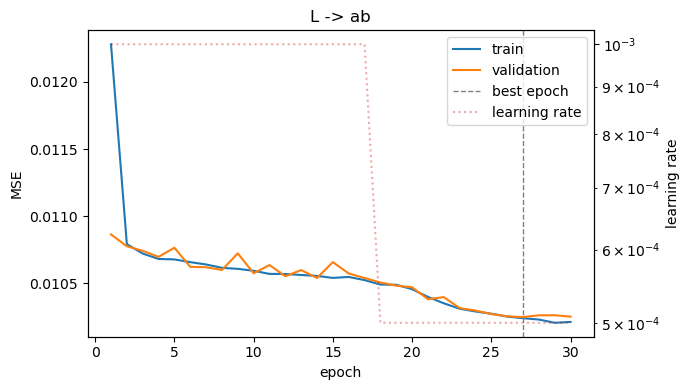

Test MSE on ab: 0.010076370586951574
Test MSE in RGB after recombining: 0.006000237539410591


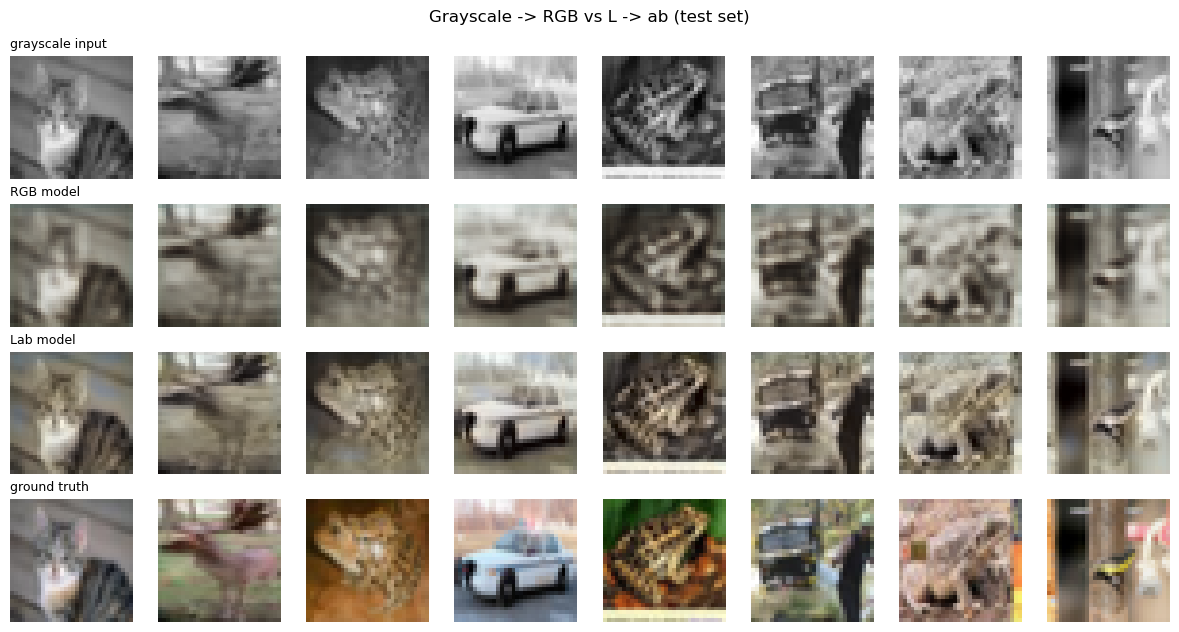

In [18]:
torch.manual_seed(SEED)
lab_model = ConfigurableCAE(**best_config, in_ch=1, out_ch=2, out_act="tanh").to(DEVICE)
lab_history = train_or_load("ex3_lab", lab_model, lab_train_loader, lab_val_loader, lab_test_loader,
                            epochs=COL_EPOCHS)
plot_learning_curve(lab_history, "L -> ab")

ab_pred = predict(lab_model, L_test)
lab_pred = lab_to_rgb(L_test, ab_pred)
print("Test MSE on ab:", lab_history["test_loss"])
print("Test MSE in RGB after recombining:", F.mse_loss(lab_pred, x_test).item())

show_rows({"grayscale input": g_test, "RGB model": rgb_pred, "Lab model": lab_pred, "ground truth": x_test},
          title="Grayscale -> RGB vs L -> ab (test set)")

### 5.3 Improvements
The two models above are limited in two ways:
1. **Capacity and detail.** The baseline-style network is tiny, and everything has to pass through the bottleneck. For colourisation the bottleneck doesn't help: the output should have the same edges as the input.
2. **The MSE loss.** When the colour of an object is uncertain (a car can be red, blue or white), the colour that minimises MSE is the average, which is grayish-brown. So the predictions are expected to be **desaturated**.

To address the first point we try a small **U-Net**: a deeper encoder-decoder with **skip connections** that pass the encoder feature maps directly to the decoder at the same resolution, plus **batch normalisation**. It still predicts ab from L.

U-Net params: 117410 | CAE params: 446
epoch   1 | train 0.01245 | val 0.01020 | lr 1.0e-03 | 20.1s
epoch   2 | train 0.00971 | val 0.00976 | lr 1.0e-03 | 16.8s
epoch   3 | train 0.00936 | val 0.00937 | lr 1.0e-03 | 16.7s
epoch   4 | train 0.00917 | val 0.00920 | lr 1.0e-03 | 17.9s
epoch   5 | train 0.00903 | val 0.00915 | lr 1.0e-03 | 18.1s
epoch   6 | train 0.00892 | val 0.00909 | lr 1.0e-03 | 18.1s
epoch   7 | train 0.00884 | val 0.00909 | lr 1.0e-03 | 9.6s
epoch   8 | train 0.00875 | val 0.00914 | lr 1.0e-03 | 5.9s
epoch   9 | train 0.00869 | val 0.00892 | lr 1.0e-03 | 5.9s
epoch  10 | train 0.00863 | val 0.00889 | lr 1.0e-03 | 5.6s
epoch  11 | train 0.00855 | val 0.00880 | lr 1.0e-03 | 5.9s
epoch  12 | train 0.00849 | val 0.00900 | lr 1.0e-03 | 5.9s
epoch  13 | train 0.00843 | val 0.00888 | lr 1.0e-03 | 6.0s
epoch  14 | train 0.00837 | val 0.00881 | lr 1.0e-03 | 5.8s
epoch  15 | train 0.00817 | val 0.00880 | lr 5.0e-04 | 5.9s
epoch  16 | train 0.00811 | val 0.00887 | lr 5.0e-04 | 

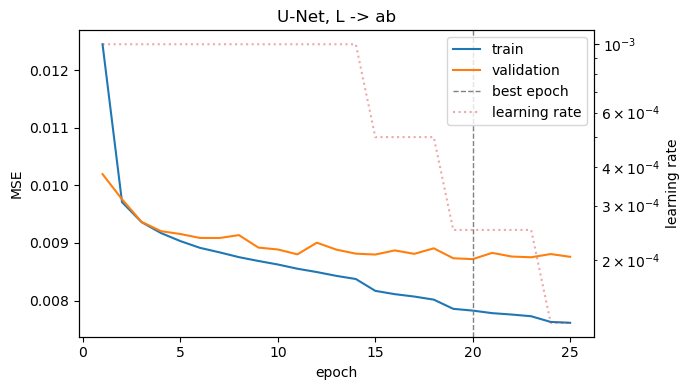

In [19]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
    )


class UNetColouriser(nn.Module):
    def __init__(self, ch=(16, 32, 64), in_ch=1, out_ch=2):
        super().__init__()
        self.enc1 = conv_block(in_ch, ch[0])                    # 32x32
        self.enc2 = conv_block(ch[0], ch[1])                    # 16x16
        self.bottleneck = conv_block(ch[1], ch[2])              # 8x8
        self.up2 = nn.ConvTranspose2d(ch[2], ch[1], 2, stride=2)
        self.dec2 = conv_block(2 * ch[1], ch[1])                # 16x16, input = upsampled + skip
        self.up1 = nn.ConvTranspose2d(ch[1], ch[0], 2, stride=2)
        self.dec1 = conv_block(2 * ch[0], ch[0])                # 32x32
        self.out = nn.Conv2d(ch[0], out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        b = self.bottleneck(F.max_pool2d(e2, 2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return torch.tanh(self.out(d1))


torch.manual_seed(SEED)
unet = UNetColouriser().to(DEVICE)
print("U-Net params:", count_params(unet), "| CAE params:", count_params(lab_model))
unet_history = train_or_load("ex3_unet_lab", unet, lab_train_loader, lab_val_loader, lab_test_loader,
                             epochs=COL_EPOCHS)
plot_learning_curve(unet_history, "U-Net, L -> ab")

ab_unet = predict(unet, L_test)
unet_pred = lab_to_rgb(L_test, ab_unet)

mean chroma of the real test images: 14.55


,params,test RGB MSE,mean chroma
model,,,
grayscale copied (reference),0,0.00659,0.00
CAE gray -> RGB,483,0.00789,5.67
CAE L -> ab,446,0.00600,6.74
U-Net L -> ab,117410,0.00506,9.55


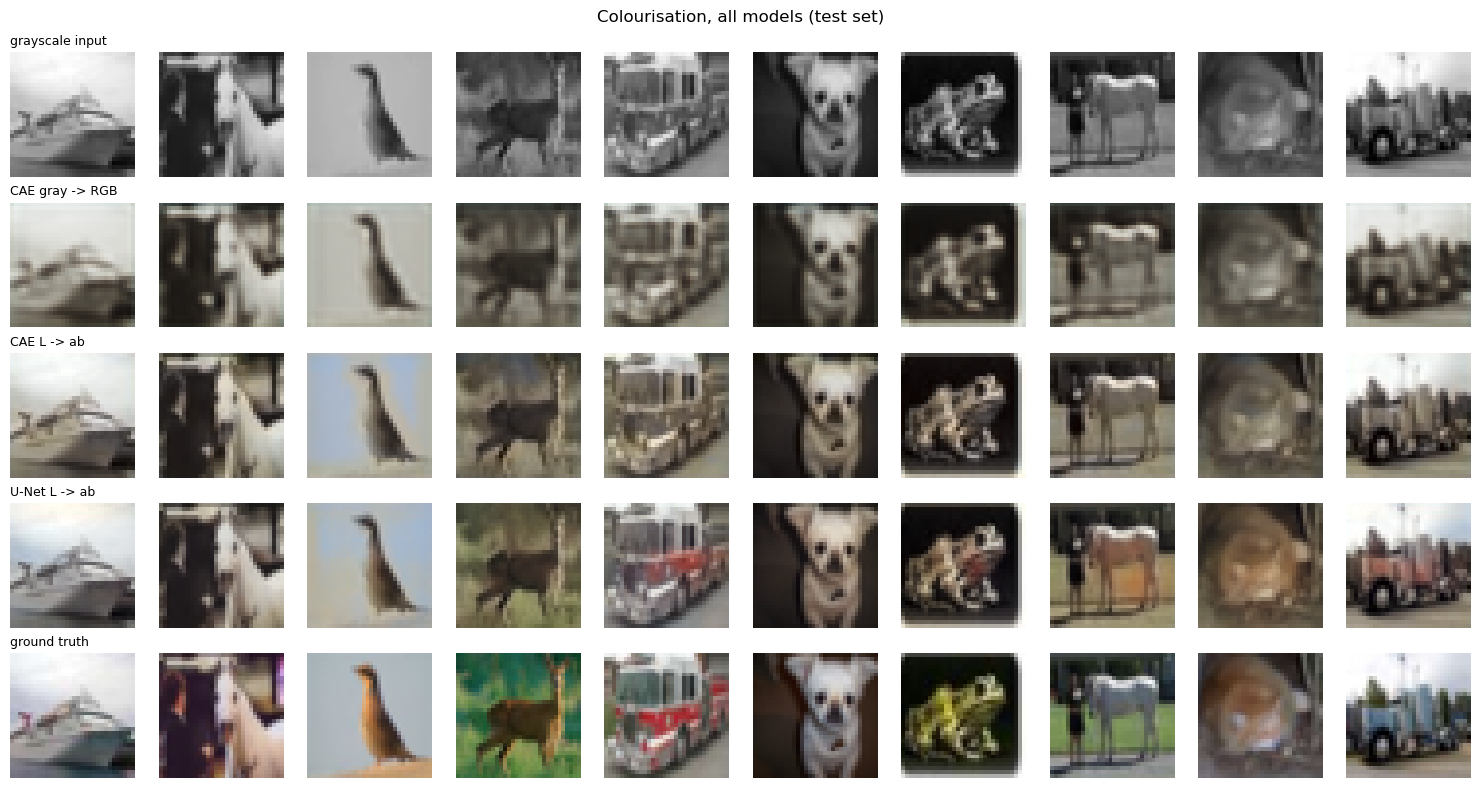

In [20]:
# summary of the three colourisation models
_, ab_rgb_model = rgb_to_lab(rgb_pred.clamp(0, 1))
summary = pd.DataFrame({
    "model": ["grayscale copied (reference)", "CAE gray -> RGB", "CAE L -> ab", "U-Net L -> ab"],
    "params": [0, count_params(rgb_model), count_params(lab_model), count_params(unet)],
    "test RGB MSE": [gray_copy_mse, F.mse_loss(rgb_pred, x_test).item(),
                     F.mse_loss(lab_pred, x_test).item(), F.mse_loss(unet_pred, x_test).item()],
    "mean chroma": [0.0, chroma(ab_rgb_model), chroma(ab_pred), chroma(ab_unet)],
}).set_index("model")
print("mean chroma of the real test images:", round(chroma(ab_test), 2))
display(summary.style.format({"test RGB MSE": "{:.5f}", "mean chroma": "{:.2f}"}))

idx = torch.arange(16, 26)
show_rows({"grayscale input": g_test[idx], "CAE gray -> RGB": rgb_pred[idx], "CAE L -> ab": lab_pred[idx],
           "U-Net L -> ab": unet_pred[idx], "ground truth": x_test[idx]}, n=10,
          title="Colourisation, all models (test set)")

## Try

trainable params: 372 | total: 483
epoch   1 | train 0.02179 | val 0.01167 | lr 1.0e-03 | 3.1s
epoch   2 | train 0.01036 | val 0.00965 | lr 1.0e-03 | 2.4s
epoch   3 | train 0.00944 | val 0.00912 | lr 1.0e-03 | 2.5s
epoch   4 | train 0.00904 | val 0.00881 | lr 1.0e-03 | 2.5s
epoch   5 | train 0.00877 | val 0.00860 | lr 1.0e-03 | 2.4s
epoch   6 | train 0.00859 | val 0.00848 | lr 1.0e-03 | 2.5s
epoch   7 | train 0.00845 | val 0.00833 | lr 1.0e-03 | 2.3s
epoch   8 | train 0.00834 | val 0.00824 | lr 1.0e-03 | 2.7s
epoch   9 | train 0.00826 | val 0.00813 | lr 1.0e-03 | 2.6s
epoch  10 | train 0.00818 | val 0.00807 | lr 1.0e-03 | 2.5s
epoch  11 | train 0.00813 | val 0.00802 | lr 1.0e-03 | 2.6s
epoch  12 | train 0.00809 | val 0.00804 | lr 1.0e-03 | 2.4s
epoch  13 | train 0.00803 | val 0.00794 | lr 1.0e-03 | 2.3s
epoch  14 | train 0.00800 | val 0.00793 | lr 1.0e-03 | 2.6s
epoch  15 | train 0.00796 | val 0.00789 | lr 1.0e-03 | 2.4s
epoch  16 | train 0.00794 | val 0.00787 | lr 1.0e-03 | 2.3s
epoch

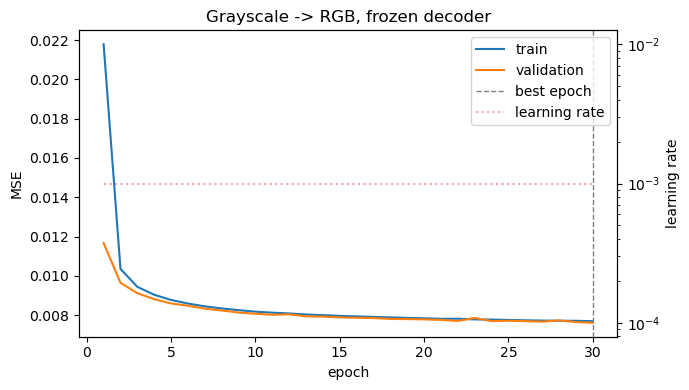

decoder unchanged: True
Test MSE, frozen decoder: 0.007673294447362423
Test MSE, all trainable (5.1): 0.007891081410149733
Test MSE, grayscale copied: 0.0065925936214625835


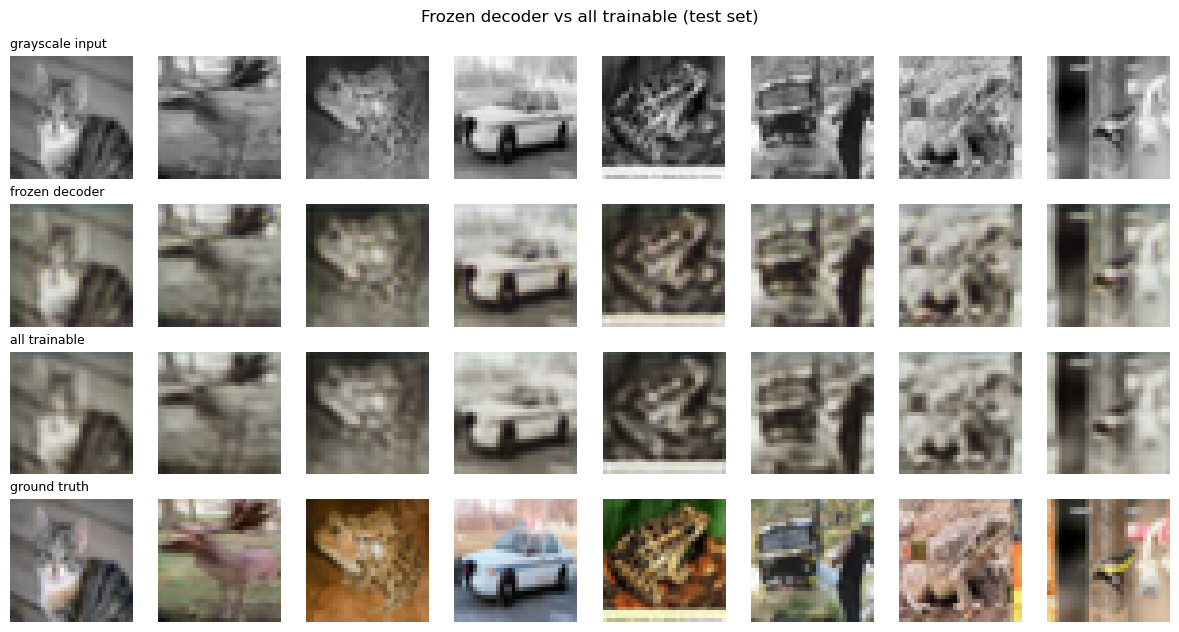

In [22]:
# take the decoder of the best RGB autoencoder from exercise 2 and freeze it
best_ae = exp_models[best_name]
frozen_decoder = best_ae.decoder
for p in frozen_decoder.parameters():
    p.requires_grad = False
decoder_before = copy.deepcopy(frozen_decoder.state_dict())

# new encoder with the same architecture, but with the grayscale image as input
torch.manual_seed(SEED)
gray_encoder = ConfigurableCAE(**best_config, in_ch=1).encoder

frozen_model = nn.Sequential(gray_encoder, frozen_decoder).to(DEVICE)
print("trainable params:", count_params(frozen_model), "| total:", sum(p.numel() for p in frozen_model.parameters()))

frozen_history = train_or_load("ex3_frozen_decoder", frozen_model, col_train_loader, col_val_loader,
                               col_test_loader, epochs=COL_EPOCHS)
plot_learning_curve(frozen_history, "Grayscale -> RGB, frozen decoder")

# the decoder weights should not have moved
print("decoder unchanged:", all(torch.equal(decoder_before[k], v) for k, v in frozen_decoder.state_dict().items()))

frozen_pred = predict(frozen_model, g_test)
print("Test MSE, frozen decoder:", frozen_history["test_loss"])
print("Test MSE, all trainable (5.1):", rgb_history["test_loss"])
print("Test MSE, grayscale copied:", gray_copy_mse)

show_rows({"grayscale input": g_test, "frozen decoder": frozen_pred, "all trainable": rgb_pred,
           "ground truth": x_test}, title="Frozen decoder vs all trainable (test set)")

trainable params: 483
epoch   1 | train 0.00766 | val 0.00761 | lr 2.0e-04 | 2.9s
epoch   2 | train 0.00764 | val 0.00763 | lr 2.0e-04 | 2.4s
epoch   3 | train 0.00762 | val 0.00755 | lr 2.0e-04 | 2.4s
epoch   4 | train 0.00761 | val 0.00754 | lr 2.0e-04 | 3.2s
epoch   5 | train 0.00760 | val 0.00754 | lr 2.0e-04 | 2.7s
epoch   6 | train 0.00759 | val 0.00756 | lr 2.0e-04 | 2.8s
epoch   7 | train 0.00759 | val 0.00755 | lr 2.0e-04 | 2.8s
epoch   8 | train 0.00757 | val 0.00751 | lr 1.0e-04 | 2.6s
epoch   9 | train 0.00757 | val 0.00753 | lr 1.0e-04 | 4.1s
epoch  10 | train 0.00757 | val 0.00750 | lr 1.0e-04 | 2.8s
epoch  11 | train 0.00756 | val 0.00750 | lr 1.0e-04 | 2.7s
epoch  12 | train 0.00756 | val 0.00749 | lr 1.0e-04 | 2.6s
epoch  13 | train 0.00756 | val 0.00749 | lr 1.0e-04 | 2.6s
epoch  14 | train 0.00755 | val 0.00749 | lr 1.0e-04 | 2.4s
epoch  15 | train 0.00755 | val 0.00749 | lr 1.0e-04 | 2.4s
epoch  16 | train 0.00755 | val 0.00749 | lr 1.0e-04 | 2.6s
epoch  17 | train 

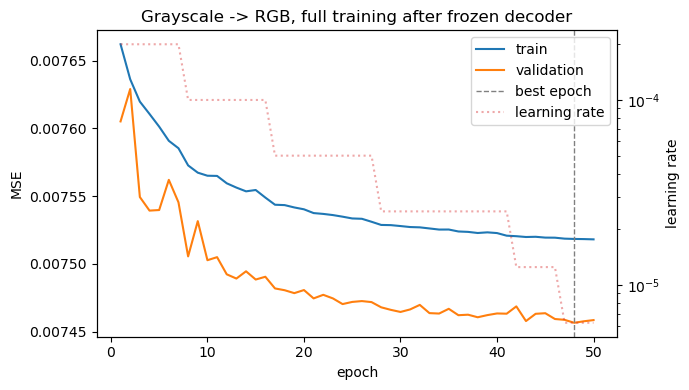

Test MSE, full training: 0.007528812166303397
Test MSE, frozen decoder: 0.007673294447362423
Test MSE, all trainable from scratch (5.1): 0.007891081410149733
Test MSE, grayscale copied: 0.0065925936214625835


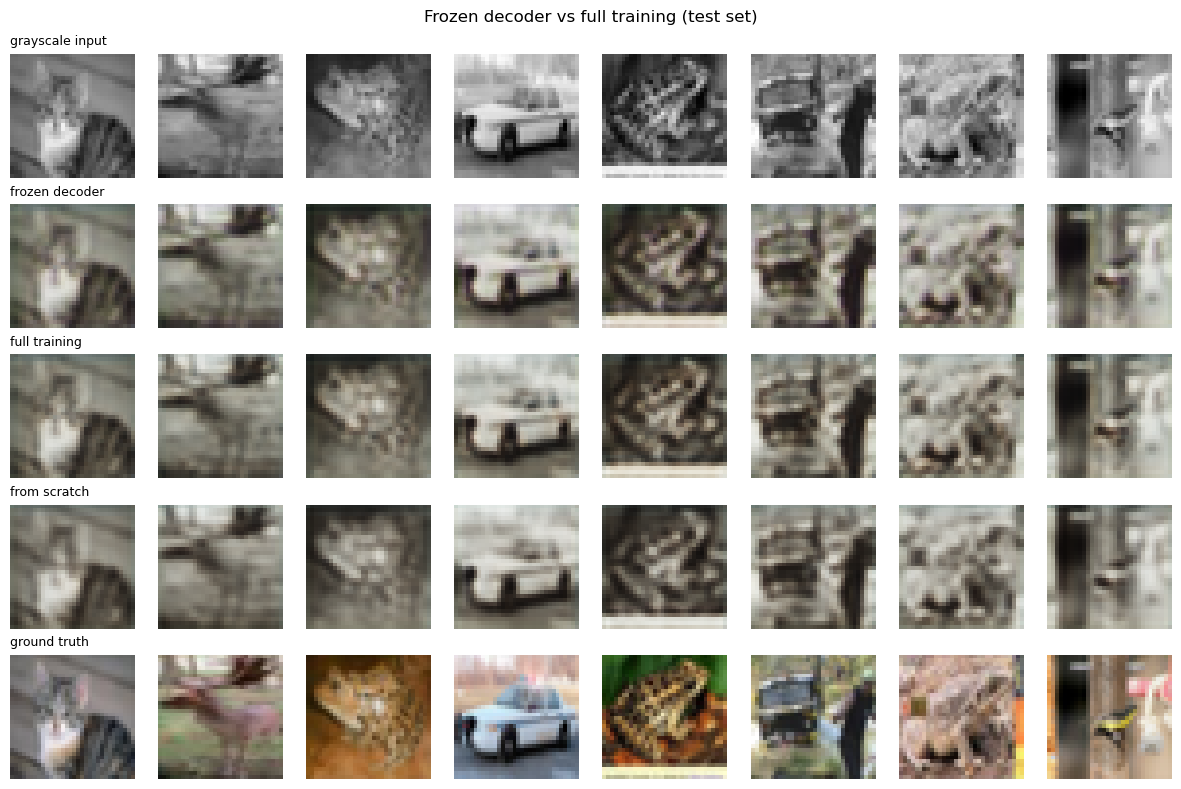

In [23]:
# start from the frozen-decoder model and now train everything, encoder and decoder
# deepcopy so the decoder of the exercise 2 autoencoder is not changed
finetune_model = copy.deepcopy(frozen_model)
for p in finetune_model.parameters():
    p.requires_grad = True
print("trainable params:", count_params(finetune_model))

# lower learning rate, the weights are already in a good place
FT_LR = LR / 10
finetune_history = train_or_load("ex3_finetune", finetune_model, col_train_loader, col_val_loader,
                                 col_test_loader, epochs=EPOCHS, lr=FT_LR)
plot_learning_curve(finetune_history, "Grayscale -> RGB, full training after frozen decoder")

finetune_pred = predict(finetune_model, g_test)
print("Test MSE, full training:", finetune_history["test_loss"])
print("Test MSE, frozen decoder:", frozen_history["test_loss"])
print("Test MSE, all trainable from scratch (5.1):", rgb_history["test_loss"])
print("Test MSE, grayscale copied:", gray_copy_mse)

show_rows({"grayscale input": g_test, "frozen decoder": frozen_pred, "full training": finetune_pred,
           "from scratch": rgb_pred, "ground truth": x_test}, title="Frozen decoder vs full training (test set)")

trainable params: 1210180 | old encoder: 372
epoch   1 | train 0.00888 | val 0.00691 | lr 1.0e-03 | 124.1s
epoch   2 | train 0.00681 | val 0.00689 | lr 1.0e-03 | 57.0s
epoch   3 | train 0.00650 | val 0.00635 | lr 1.0e-03 | 23.0s
epoch   4 | train 0.00635 | val 0.00635 | lr 1.0e-03 | 20.8s
epoch   5 | train 0.00616 | val 0.00600 | lr 1.0e-03 | 18.0s
epoch   6 | train 0.00610 | val 0.00718 | lr 1.0e-03 | 18.1s
epoch   7 | train 0.00631 | val 0.00597 | lr 1.0e-03 | 17.9s
epoch   8 | train 0.00603 | val 0.00600 | lr 1.0e-03 | 17.8s
epoch   9 | train 0.00604 | val 0.00601 | lr 1.0e-03 | 18.0s
epoch  10 | train 0.00618 | val 0.00582 | lr 1.0e-03 | 17.9s
epoch  11 | train 0.00592 | val 0.00658 | lr 1.0e-03 | 17.8s
epoch  12 | train 0.00587 | val 0.00585 | lr 1.0e-03 | 17.9s
epoch  13 | train 0.00584 | val 0.00588 | lr 1.0e-03 | 18.0s
epoch  14 | train 0.00567 | val 0.00637 | lr 5.0e-04 | 18.2s
epoch  15 | train 0.00562 | val 0.00561 | lr 5.0e-04 | 17.9s
epoch  16 | train 0.00560 | val 0.00570

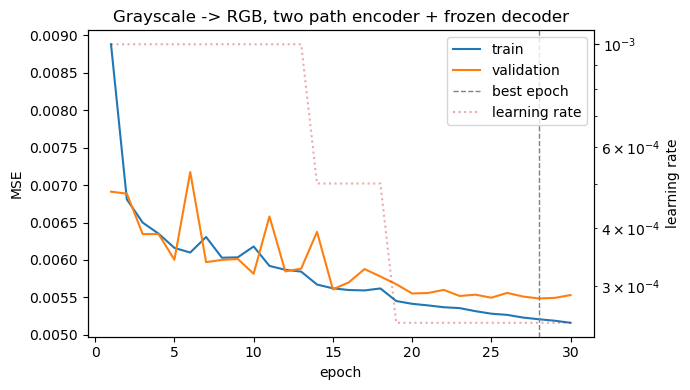

Test MSE, two path encoder: 0.005427774815509717
Test MSE, small encoder, frozen decoder: 0.007673294447362423
Test MSE, small encoder, full training: 0.007528812166303397
Test MSE, grayscale copied: 0.0065925936214625835


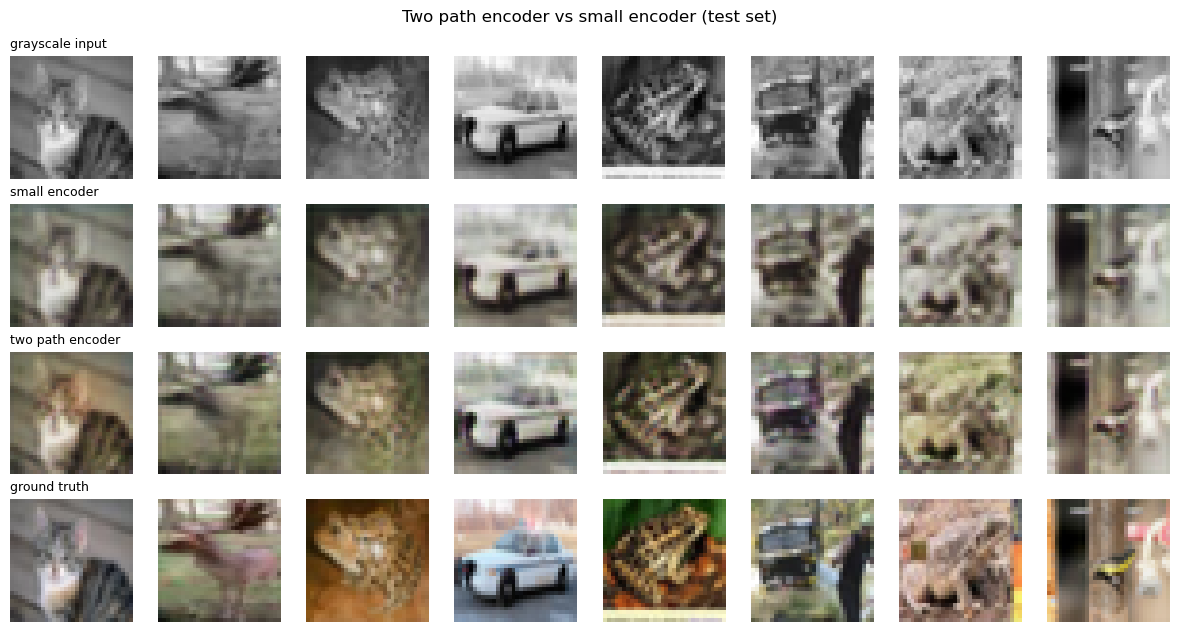

In [24]:
class TwoPathEncoder(nn.Module):
    # two parallel ways down to 16x16, then merged into the latent of the frozen decoder
    def __init__(self, in_ch=1, latent_channels=4, width=64):
        super().__init__()
        w = width
        # path 1: small 3x3 filters and max pool, keeps local detail
        self.path_pool = nn.Sequential(
            conv_block(in_ch, w),                                   # 32x32
            nn.MaxPool2d(2),                                        # 16x16
            conv_block(w, 2 * w),
        )
        # path 2: bigger 5x5 filters and a strided conv, sees more context
        self.path_stride = nn.Sequential(
            nn.Conv2d(in_ch, w, 5, padding=2), nn.BatchNorm2d(w), nn.ReLU(),
            nn.Conv2d(w, 2 * w, 5, stride=2, padding=2), nn.BatchNorm2d(2 * w), nn.ReLU(),   # 16x16
            conv_block(2 * w, 2 * w),
        )
        # concat both paths and go to the latent size
        # ReLU at the end because the decoder was trained on latents after a ReLU
        self.merge = nn.Sequential(
            conv_block(4 * w, 2 * w),
            nn.Conv2d(2 * w, latent_channels, 3, padding=1), nn.ReLU(),
        )

    def forward(self, x):
        return self.merge(torch.cat([self.path_pool(x), self.path_stride(x)], dim=1))


# same frozen decoder as before, a fresh copy so nothing above is touched
two_path_decoder = copy.deepcopy(best_ae.decoder)
for p in two_path_decoder.parameters():
    p.requires_grad = False

torch.manual_seed(SEED)
two_path_model = nn.Sequential(TwoPathEncoder(latent_channels=best_config["latent_channels"]),
                               two_path_decoder).to(DEVICE)
print("trainable params:", count_params(two_path_model), "| old encoder:", count_params(frozen_model))

two_path_history = train_or_load("ex3_two_path_encoder", two_path_model, col_train_loader, col_val_loader,
                                 col_test_loader, epochs=COL_EPOCHS)
plot_learning_curve(two_path_history, "Grayscale -> RGB, two path encoder + frozen decoder")

two_path_pred = predict(two_path_model, g_test)
print("Test MSE, two path encoder:", two_path_history["test_loss"])
print("Test MSE, small encoder, frozen decoder:", frozen_history["test_loss"])
print("Test MSE, small encoder, full training:", finetune_history["test_loss"])
print("Test MSE, grayscale copied:", gray_copy_mse)

show_rows({"grayscale input": g_test, "small encoder": frozen_pred, "two path encoder": two_path_pred,
           "ground truth": x_test}, title="Two path encoder vs small encoder (test set)")

params: 1438343
epoch   1 | train 0.00723 | val 0.00340 | lr 1.0e-03 | 26.0s
epoch   2 | train 0.00302 | val 0.00207 | lr 1.0e-03 | 25.9s
epoch   3 | train 0.00194 | val 0.00170 | lr 1.0e-03 | 26.1s
epoch   4 | train 0.00164 | val 0.00151 | lr 1.0e-03 | 25.6s
epoch   5 | train 0.00132 | val 0.00163 | lr 1.0e-03 | 25.2s
epoch   6 | train 0.00130 | val 0.00103 | lr 1.0e-03 | 25.2s
epoch   7 | train 0.00125 | val 0.00086 | lr 1.0e-03 | 25.3s
epoch   8 | train 0.00110 | val 0.00107 | lr 1.0e-03 | 25.2s
epoch   9 | train 0.00104 | val 0.00078 | lr 1.0e-03 | 25.3s
epoch  10 | train 0.00105 | val 0.00101 | lr 1.0e-03 | 25.5s
epoch  11 | train 0.00092 | val 0.00118 | lr 1.0e-03 | 25.2s
epoch  12 | train 0.00100 | val 0.00072 | lr 1.0e-03 | 25.3s
epoch  13 | train 0.00096 | val 0.00067 | lr 1.0e-03 | 25.0s
epoch  14 | train 0.00101 | val 0.00065 | lr 1.0e-03 | 25.2s
epoch  15 | train 0.00101 | val 0.00062 | lr 1.0e-03 | 25.6s
epoch  16 | train 0.00088 | val 0.00061 | lr 1.0e-03 | 26.1s
epoch  1

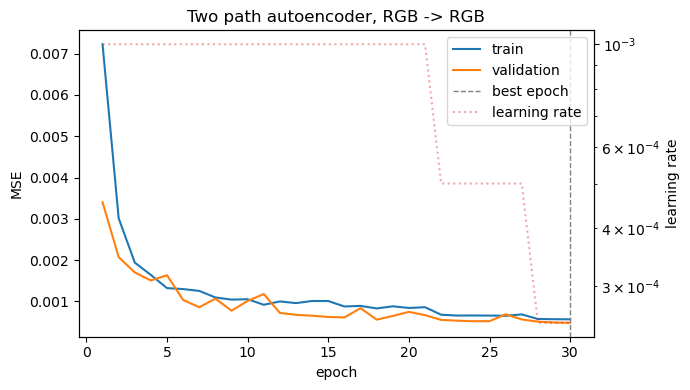

Test MSE, two path autoencoder: 0.0004713031534726421
Test MSE, best autoencoder of exercise 2: 0.002178285113846262


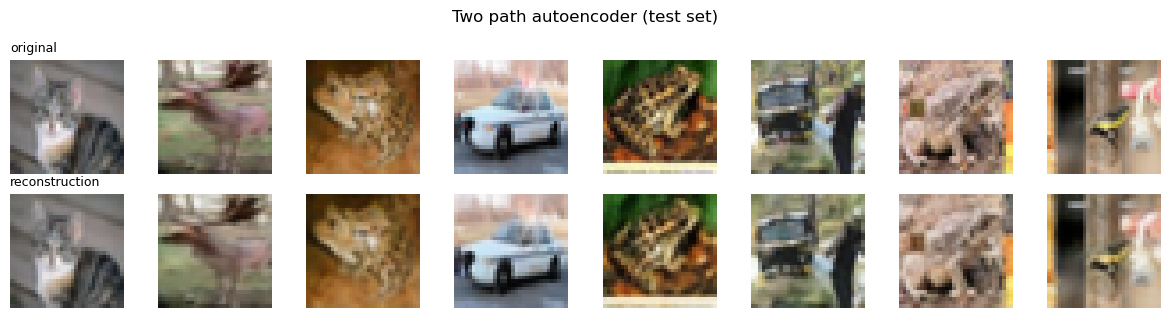

In [26]:
# RGB -> RGB autoencoder with the two path encoder and a bigger decoder than the exercise 2 one
# no BatchNorm in the decoder: once it is frozen, model.train() would still update the BN statistics
def two_path_decoder_rgb(latent_channels=4, width=64):
    w = width
    return nn.Sequential(
        nn.Conv2d(latent_channels, 2 * w, 3, padding=1), nn.ReLU(),     # 16x16
        nn.Conv2d(2 * w, 2 * w, 3, padding=1), nn.ReLU(),
        nn.ConvTranspose2d(2 * w, w, 2, stride=2), nn.ReLU(),            # 32x32
        nn.Conv2d(w, w, 3, padding=1), nn.ReLU(),
        nn.Conv2d(w, 3, 3, padding=1), nn.Sigmoid(),
    )


torch.manual_seed(SEED)
tp_rgb_ae = nn.Sequential(TwoPathEncoder(in_ch=3, latent_channels=best_config["latent_channels"]),
                          two_path_decoder_rgb(best_config["latent_channels"])).to(DEVICE)
print("params:", count_params(tp_rgb_ae))

tp_rgb_history = train_or_load("ex3_two_path_rgb_ae", tp_rgb_ae, train_loader, val_loader, test_loader,
                               epochs=COL_EPOCHS)
plot_learning_curve(tp_rgb_history, "Two path autoencoder, RGB -> RGB")
print("Test MSE, two path autoencoder:", tp_rgb_history["test_loss"])
print("Test MSE, best autoencoder of exercise 2:", evaluate(best_ae, test_loader))
show_reconstructions(tp_rgb_ae, x_test, title="Two path autoencoder (test set)")

In [ ]:
# same trick as before: freeze the decoder of the RGB autoencoder and train a new encoder on gray images
tp_frozen_decoder = copy.deepcopy(tp_rgb_ae[1])
for p in tp_frozen_decoder.parameters():
    p.requires_grad = False
tp_decoder_before = copy.deepcopy(tp_frozen_decoder.state_dict())

torch.manual_seed(SEED)
tp_gray_model = nn.Sequential(TwoPathEncoder(in_ch=1, latent_channels=best_config["latent_channels"]),
                              tp_frozen_decoder).to(DEVICE)
print("trainable params:", count_params(tp_gray_model), "| total:", sum(p.numel() for p in tp_gray_model.parameters()))

tp_gray_history = train_or_load("ex3_two_path_gray_frozen", tp_gray_model, col_train_loader, col_val_loader,
                                col_test_loader, epochs=COL_EPOCHS)
plot_learning_curve(tp_gray_history, "Grayscale -> RGB, two path encoder + frozen two path decoder")
print("decoder unchanged:", all(torch.equal(tp_decoder_before[k], v) for k, v in tp_frozen_decoder.state_dict().items()))


def split_error(pred, target):
    # brightness = mean of the 3 channels, colour = the rest, the two add up to the MSE
    mp, mt = pred.mean(1, keepdim=True), target.mean(1, keepdim=True)
    return ((mp - mt) ** 2).mean().item(), (((pred - mp) - (target - mt)) ** 2).mean().item()


tp_gray_pred = predict(tp_gray_model, g_test)
for name, pred in [("grayscale copied", g_test.repeat(1, 3, 1, 1)),
                   ("two path autoencoder, colour input", predict(tp_rgb_ae, x_test)),
                   ("small encoder, full training", finetune_pred),
                   ("two path, frozen decoder", tp_gray_pred)]:
    pred = pred.clamp(0, 1)
    b, c = split_error(pred, x_test)
    print(f"{name:<36} total {F.mse_loss(pred, x_test).item():.5f} | brightness {b:.5f} | colour {c:.5f}")

show_rows({"grayscale input": g_test, "small encoder": finetune_pred, "two path, frozen decoder": tp_gray_pred,
           "ground truth": x_test}, title="Two path encoder with frozen two path decoder (test set)")

trainable params: 1210180 | total: 1433991
epoch   1 | train 0.00760 | val 0.00632 | lr 1.0e-03 | 22.5s
epoch   2 | train 0.00592 | val 0.00620 | lr 1.0e-03 | 22.5s
epoch   3 | train 0.00575 | val 0.00562 | lr 1.0e-03 | 22.3s
epoch   4 | train 0.00564 | val 0.00625 | lr 1.0e-03 | 22.4s
epoch   5 | train 0.00553 | val 0.00561 | lr 1.0e-03 | 22.4s
epoch   6 | train 0.00549 | val 0.00669 | lr 1.0e-03 | 22.8s
epoch   7 | train 0.00546 | val 0.00568 | lr 1.0e-03 | 22.3s
epoch   8 | train 0.00543 | val 0.00530 | lr 1.0e-03 | 21.8s
epoch   9 | train 0.00541 | val 0.00531 | lr 1.0e-03 | 22.2s
epoch  10 | train 0.00537 | val 0.00557 | lr 1.0e-03 | 22.0s
epoch  11 | train 0.00534 | val 0.00549 | lr 1.0e-03 | 22.1s
epoch  12 | train 0.00517 | val 0.00521 | lr 5.0e-04 | 22.2s
epoch  13 | train 0.00515 | val 0.00540 | lr 5.0e-04 | 22.6s
epoch  14 | train 0.00514 | val 0.00535 | lr 5.0e-04 | 22.7s
epoch  15 | train 0.00508 | val 0.00521 | lr 5.0e-04 | 22.4s
epoch  16 | train 0.00496 | val 0.00516 | 

trainable params: 1433991
epoch   1 | train 0.00485 | val 0.00527 | lr 2.0e-04 | 29.4s
epoch   2 | train 0.00476 | val 0.00509 | lr 2.0e-04 | 25.8s
epoch   3 | train 0.00472 | val 0.00526 | lr 2.0e-04 | 24.8s
epoch   4 | train 0.00469 | val 0.00508 | lr 2.0e-04 | 24.7s
epoch   5 | train 0.00465 | val 0.00518 | lr 2.0e-04 | 24.7s
epoch   6 | train 0.00460 | val 0.00523 | lr 2.0e-04 | 24.9s
epoch   7 | train 0.00455 | val 0.00545 | lr 2.0e-04 | 24.9s
epoch   8 | train 0.00443 | val 0.00518 | lr 1.0e-04 | 24.0s
epoch   9 | train 0.00438 | val 0.00518 | lr 1.0e-04 | 23.9s
Early stopping at epoch 9 (best epoch 4, val 0.00508)


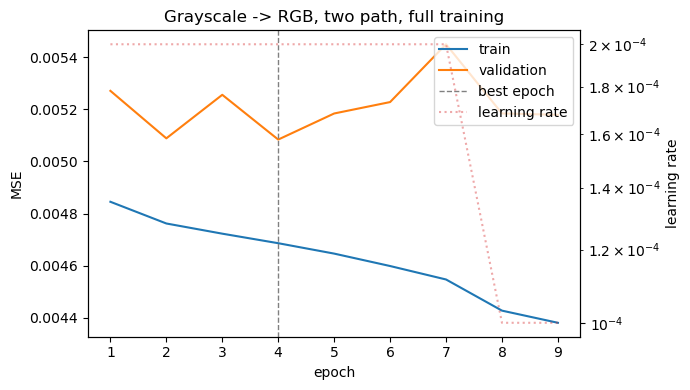

NameError: name 'tp_gray_pred' is not defined

In [28]:
# start from the model above and train the whole network, encoder and decoder, for at most 10 epochs
# deepcopy so the frozen model above stays as it is
tp_finetune_model = copy.deepcopy(tp_gray_model)
for p in tp_finetune_model.parameters():
    p.requires_grad = True
print("trainable params:", count_params(tp_finetune_model))

tp_finetune_history = train_or_load("ex3_two_path_finetune", tp_finetune_model, col_train_loader, col_val_loader,
                                    col_test_loader, epochs=10, lr=LR / 10)
plot_learning_curve(tp_finetune_history, "Grayscale -> RGB, two path, full training")

tp_finetune_pred = predict(tp_finetune_model, g_test)
for name, pred in [("grayscale copied", g_test.repeat(1, 3, 1, 1)),
                   ("two path, frozen decoder", tp_gray_pred),
                   ("two path, full training", tp_finetune_pred)]:
    pred = pred.clamp(0, 1)
    b, c = split_error(pred, x_test)
    print(f"{name:<36} total {F.mse_loss(pred, x_test).item():.5f} | brightness {b:.5f} | colour {c:.5f}")

show_rows({"grayscale input": g_test, "frozen decoder": tp_gray_pred, "full training": tp_finetune_pred,
           "ground truth": x_test}, title="Two path, frozen decoder vs full training (test set)")

**Discussion.** _To be written from the final run._

## 6. Conclusion
_To be written from the final run._